# Does Coinbase lead Kraken? The appendix

*The checks behind [the essay](price-discovery.ipynb), for a reader refereeing it.*

The essay measures three ways whether Coinbase's price moves before Kraken's. This appendix
holds what a referee would check before believing it: where the numbers came from, how the
forecast was validated, the reverse direction, stale books, leakage, calibration, where the
forecast's accuracy concentrates, how the information share depends on its settings, whether
the result depends on the clock the prices are timed by, and a last cell that recomputes every
published number from the committed files. As in the essay, *lead* means timing: one price
moves first and the other follows.

The heavy lifting happened in [crosstick](https://github.com/ryanp2718/crosstick), a streaming
market-data platform: capture, order-book reconstruction, the feature build and the
walk-forward fit. What is published here is its output: the out-of-sample predictions, one row
per test bar, the one-second prices, and the run records that describe how both were produced.
Everything below recomputes from those files, with no database to connect to, no object store,
no credentials and no feature cache.

In [1]:
from pathlib import Path
import json
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyarrow.parquet as pq

from research.infoshare import information_shares
from research.runs import read_oos
from research.validation import (
    Blocks,
    class_confidence_intervals,
    confidence_intervals,
    coverage_confidence_intervals,
)

DATA = next(p for p in (Path("data"), Path("../data")) if p.exists())


def record(tag):
    """The run record: everything about a run except the rows."""
    return json.loads((DATA / f"record_{tag}.json").read_text(encoding="utf-8"))


def rows(tag, model="gbt"):
    """The pooled out-of-sample rows for one model."""
    return read_oos(pl.read_parquet(DATA / f"oos_{tag}.parquet"))[model]


real, placebo, backward = record("real"), record("placebo"), record("reverse")
prices = pl.read_parquet(DATA / "prices.parquet").sort("ts_ns")
print(f"loaded {len(list(DATA.glob('oos_*.parquet')))} prediction files and "
      f"{prices.height:,} one-second prices from {DATA.as_posix()}/")

loaded 3 prediction files and 1,529,334 one-second prices from ../data/


In [2]:
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, PALE = "#e1e0d9", "#c3c2b7", "#e1e0d9"
# The essay's venue colours. A forecast takes the colour of the venue whose book it reads,
# and the controls are grey.
COINBASE, KRAKEN = "#2a78d6", "#eb6834"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 130, "font.size": 10,
})


def interval(ax, y, values, color, pad=0.004):
    """One point estimate and its interval, drawn as a dot on a bar."""
    point, low, high = values
    ax.plot([low, high], [y, y], color=color, lw=2.5, solid_capstyle="round", zorder=3)
    ax.plot([point], [y], "o", color=color, ms=9, zorder=4)
    ax.text(high + pad, y, f"{point:.4f}", va="center", fontsize=9.5, color=INK)

## 1. Where the numbers come from

Each run wrote a record naming the commit it ran at, a digest of the feature-building code, a
digest of the declared feature schema, and one fingerprint per day of source data. Two runs
that agree on all of those and disagree on a number would be a determinism bug.

The experiment is three runs: the forecast, the same forecast pointed the other way, and a
control with its target displaced. They differ only in their specs. The one-second prices
behind the essay's charts and the information share carry the same provenance in their file
metadata.

In [3]:
for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    p, s = rec["provenance"], rec["spec"]
    print(
        f"{tag:8s} predict {s['predict_venue']:9s} placebo={str(s['placebo']):5s} "
        f"sha {p['git_sha']} dirty={p['git_dirty']} "
        f"builder {p['builder_fingerprint']} schema {p['feature_schema_digest']}"
    )

# The three runs have to share a data vintage, or a difference between them could be the
# data moving rather than the thing under test.
assert not any(rec["provenance"]["git_dirty"] for rec in (real, placebo, backward))
assert real["provenance"]["source_fingerprints"] == placebo["provenance"]["source_fingerprints"]
assert real["provenance"]["source_fingerprints"] == backward["provenance"]["source_fingerprints"]
print(f"\nall three share {len(real['provenance']['source_fingerprints'])} source fingerprints")
print("packages:", real["provenance"]["packages"])

# The prices were exported from the same feature cache, and their metadata says which.
meta = json.loads(pq.read_schema(DATA / "prices.parquet").metadata[b"crosstick"])
for key in ("git_sha", "builder_fingerprint", "source_fingerprints"):
    assert meta[key] == real["provenance"][key], key
assert prices.height == real["n_rows"]
print(f"prices   sha {meta['git_sha']} builder {meta['builder_fingerprint']}, "
      f"the same source fingerprints, and the run's {prices.height:,} rows")

real     predict kraken    placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
reverse  predict coinbase  placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
placebo  predict kraken    placebo=True  sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c

all three share 20 source fingerprints
packages: {'scikit-learn': '1.9.0', 'numpy': '2.4.6', 'polars': '1.43.2', 'pyarrow': '25.0.0'}
prices   sha fb7a22d builder 8f96b676, the same source fingerprints, and the run's 1,529,334 rows


## 2. The data and the target

The raw stream of book updates and trades is aggregated into one-second bars. The target is
Kraken's mid-price return five bars ahead, in basis points, and the forecast sees none of
Kraken's own features: all 27 are Coinbase's, so the inputs share no term with the target.
They cover the book (the spread, size at the best prices, depth and its imbalance within five
and ten levels, the microprice's deviation from the mid), order flow (order-flow imbalance,
signed and total volume, trade counts) and Coinbase's own recent returns, the flow and return
features each over several windows. A bar counts only if both books have updated within the
last five seconds; section 5 tightens that.

In [4]:
spec = real["spec"]
names = real["feature_names"]
assert not any(f.startswith(spec["predict_venue"]) for f in names)
print(f"target {spec['target']}: {spec['predict_venue']}'s mid return {spec['horizon']} bars "
      f"ahead, in bps")
print(f"{len(names)} features, none from {spec['predict_venue']}:")
print(textwrap.fill(", ".join(names), 92, initial_indent="  ", subsequent_indent="  "))

target = rows("real")
print(f"\n{real['n_rows']:,} usable rows from {real['n_rows_before']:,} "
      f"({real['n_rows'] / real['n_rows_before']:.1%} survive the "
      f"<={spec['max_age_ms']}ms staleness cut)")
print(f"{len(target.y):,} out-of-sample bars on {real['n_test_dates']} test dates")

flat = float((target.y == 0).mean())
up, down = float((target.y > 0).mean()), float((target.y < 0).mean())
print(f"\nbars where Kraken's mid does not move: {flat:.1%} (up {up:.2%}, down {down:.2%})")
print(f"always guessing 'up' among the bars that moved: right {up / (up + down):.1%} of the time")

target y_kraken_ret_bps_5: kraken's mid return 5 bars ahead, in bps
27 features, none from kraken:
  coinbase_spread_bps, coinbase_imbalance, coinbase_micro_dev, coinbase_depth_imb_5,
  coinbase_depth_imb_10, coinbase_bid_span_bps, coinbase_ask_span_bps, coinbase_depth_10,
  coinbase_bid_sz, coinbase_ask_sz, coinbase_ofi, coinbase_ret_bps_1, coinbase_ret_bps_5,
  coinbase_ret_bps_30, coinbase_ret_bps_300, coinbase_ofi_5, coinbase_ofi_30,
  coinbase_ofi_300, coinbase_signed_vol, coinbase_volume, coinbase_n_trades,
  coinbase_signed_vol_5, coinbase_volume_5, coinbase_signed_vol_30, coinbase_volume_30,
  coinbase_signed_vol_300, coinbase_volume_300

1,529,334 usable rows from 1,652,254 (92.6% survive the <=5000ms staleness cut)
180,195 out-of-sample bars on 12 test dates

bars where Kraken's mid does not move: 78.9% (up 10.82%, down 10.28%)
always guessing 'up' among the bars that moved: right 51.3% of the time


Nearly four bars in five do not move at all. A forecast of no change would be right on 78.9% of
them and say nothing, so accuracy is not reported. The metrics are:

- **R² against a zero forecast**: whether the prediction beats "no change".
- **Hit rate**: right calls over calls made, counting only bars where the mid moved and the model
  called a direction. Among the bars that moved, slightly more went up than down, so the mark to
  clear is 51.3%, not 50%.
- **Precision outside a dead zone**, in section 8: counting only moves larger than half the
  prevailing spread.

## 3. How the forecast is validated

**Walk forward, never shuffle.** Four folds, each training on every day before a cut and testing
on the three days after it. **An embargo at every boundary**: the last `horizon` rows before each
cut are dropped, so no training row's forward window reaches into the test period. **Early
stopping on its own slice**: the newest 15% of training rows, itself embargoed, so when to stop
is not decided by test data.

**Intervals come from date-block bootstraps.** Adjacent seconds are not independent, so
resampling rows would give intervals far too tight. Resampling whole days does not, on the
assumption the protocol rests on: dependence does not survive a date boundary.

fold 0: trains through 07-04 (15% of its rows kept for early stopping), tests 07-05, 07-06, 07-10
fold 1: trains through 07-10 (15% of its rows kept for early stopping), tests 07-11, 07-12, 07-13
fold 2: trains through 07-13 (15% of its rows kept for early stopping), tests 07-14, 07-15, 07-16
fold 3: trains through 07-16 (15% of its rows kept for early stopping), tests 07-17, 07-18, 07-26
intervals: 1,000 date-block draws

capture is missing 07-07 to 07-09 and 07-19 to 07-25


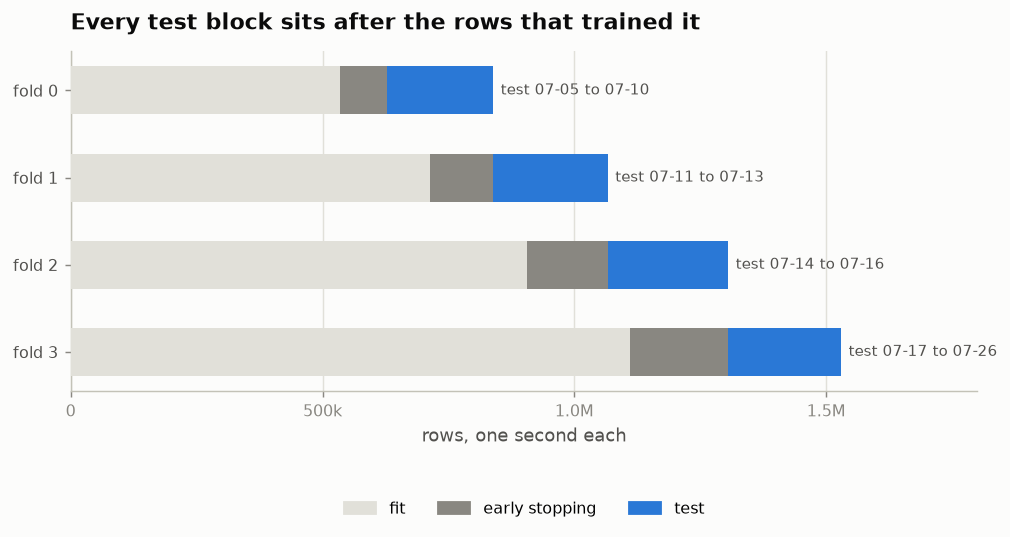

In [5]:
for i, fold in enumerate(real["folds"]):
    print(f"fold {i}: trains through {fold['train_dates'][-1][5:]} "
          f"({fold['n_val'] / (fold['n_train'] + fold['n_val']):.0%} of its rows kept for "
          f"early stopping), tests {', '.join(d[5:] for d in fold['test_dates'])}")
print(f"intervals: {spec['n_boot']:,} date-block draws")

day = np.array(spec["dates"], dtype="datetime64[D]")
holes = [(str(a + 1)[5:], str(b - 1)[5:]) for a, b in zip(day[:-1], day[1:]) if b - a > 1]
print(f"\ncapture is missing {' and '.join(f'{a} to {b}' for a, b in holes)}")

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, fold in enumerate(real["folds"]):
    y = len(real["folds"]) - 1 - i
    fit, val, test = fold["n_train"], fold["n_val"], fold["n_test"]
    ax.barh(y, fit, left=0, height=0.55, color=PALE, zorder=3)
    ax.barh(y, val, left=fit, height=0.55, color=MUTED, zorder=3)
    ax.barh(y, test, left=fit + val, height=0.55, color=COINBASE, zorder=3)
    ax.text(fit + val + test + 15000, y,
            f"test {fold['test_dates'][0][5:]} to {fold['test_dates'][-1][5:]}",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(real["folds"])))
ax.set_yticklabels([f"fold {i}" for i in reversed(range(len(real["folds"])))], color=INK2)
ax.set_xticks([0, 500_000, 1_000_000, 1_500_000])
ax.set_xticklabels(["0", "500k", "1.0M", "1.5M"])
ax.set_xlabel("rows, one second each")
ax.set_title("Every test block sits after the rows that trained it")
ax.set_xlim(0, 1_800_000)
ax.grid(axis="x", zorder=0)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in (PALE, MUTED, COINBASE)],
          ["fit", "early stopping", "test"],
          loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
plt.show()

Capture has two holes, 07-07 to 07-09 and 07-19 to 07-25. The last fold therefore trains
through 07-16 and tests on 07-17, 07-18 and 07-26, across a week-long gap. The next section
comes back to it.

## 4. The headline, and two models that did not make it

The essay reports the gradient-boosted tree. It was run alongside two ridge regressions on the
same folds, one on the order-flow features only and one on all 27, and all three are scored
against the zero forecast. The intervals are recomputed from the committed rows rather than read
out of the record.

In [6]:
models = ["ridge_ofi", "ridge_all", "gbt"]
labels = ["ridge, order flow only", "ridge, all 27 features", "gradient boosting"]
pooled = {name: confidence_intervals(o) for name, o in
          read_oos(pl.read_parquet(DATA / "oos_real.parquet")).items()}

print(f"{'model':10s} {'R2 vs zero':>27s} {'hit rate':>25s}")
for name in models:
    r2, hit = pooled[name]["r2_vs_zero"], pooled[name]["hit_rate"]
    print(f"{name:10s} {r2[0]:8.5f} [{r2[1]:7.5f}, {r2[2]:7.5f}] "
          f"{hit[0]:7.4f} [{hit[1]:6.4f}, {hit[2]:6.4f}]")

# What the record said, and what the rows say, have to be the same thing.
for name in models:
    for metric in ("r2_vs_zero", "hit_rate"):
        assert np.allclose(pooled[name][metric], real["pooled"][name][metric], atol=1e-9), name
print("every interval matches the published record")

print(f"\n{'R2 by fold':10s} " + " ".join(f"{f'fold {i}':>7s}" for i in range(len(real["folds"]))))
for name in models:
    print(f"{name:10s} " + " ".join(f"{f['metrics'][name]['r2_vs_zero']:7.3f}"
                                    for f in real["folds"]))

model                       R2 vs zero                  hit rate
ridge_ofi   0.00070 [-0.09966, 0.04120]  0.7047 [0.6892, 0.7233]
ridge_all   0.03356 [-0.13461, 0.09921]  0.7352 [0.7150, 0.7585]
gbt         0.10349 [0.09075, 0.11202]  0.7572 [0.7351, 0.7805]
every interval matches the published record

R2 by fold  fold 0  fold 1  fold 2  fold 3
ridge_ofi    0.033   0.038   0.043  -0.206
ridge_all    0.091   0.077   0.098  -0.272
gbt          0.097   0.094   0.112   0.113


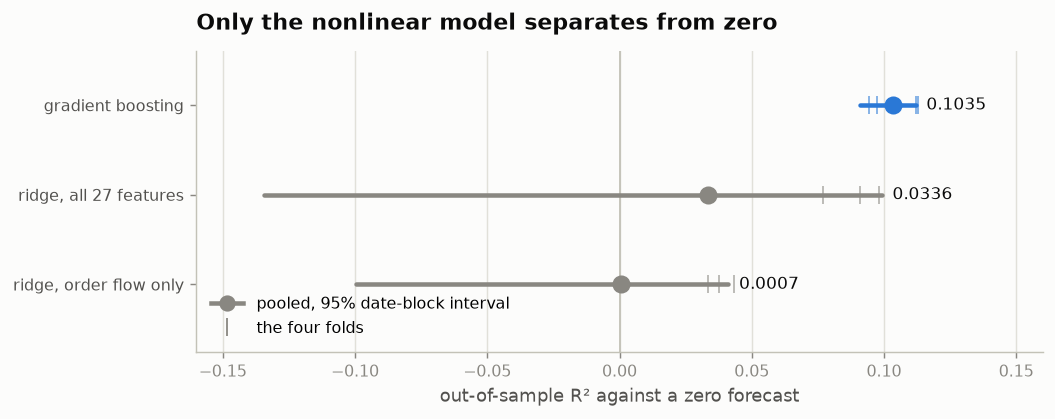

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 3))
for i, model in enumerate(models):
    color = COINBASE if model == "gbt" else MUTED
    interval(ax, i, pooled[model]["r2_vs_zero"], color)
    folds = [f["metrics"][model]["r2_vs_zero"] for f in real["folds"]]
    ax.plot(folds, [i] * len(folds), "|", color=color, ms=10, alpha=0.6, zorder=4)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(labels, color=INK2)
ax.set_xlabel("out-of-sample R² against a zero forecast")
ax.set_title("Only the nonlinear model separates from zero")
ax.set_xlim(-0.16, 0.16)
ax.set_ylim(-0.75, 2.6)
ax.grid(axis="x", zorder=0)
ax.legend([plt.Line2D([], [], color=MUTED, marker="o", ms=8, lw=2.5),
           plt.Line2D([], [], color=MUTED, marker="|", ms=10, lw=0)],
          ["pooled, 95% date-block interval", "the four folds"], loc="lower left")
plt.show()

The tree's four folds sit between 0.094 and 0.113, so no one stretch of days carries its
average. The ridges are worth something on the first three folds and fail badly on the fourth,
the one tested across the capture gap: -0.206 for the order-flow ridge and -0.272 for the
all-features ridge. That drags their pooled scores down to 0.001 and 0.034 and their intervals
well below zero. The tree posts its best fold there.

We read the difference as one of shape. Price impact is concave in size and depends on the
depth and spread an order lands in, so the same order-flow imbalance moves the price by
different amounts in different books, and a linear model cannot represent that.

## 5. The reverse direction, and stale books

The reverse run is the same 20 days, bars, feature builder, folds and model, with only the
direction changed: Kraken's book forecasting Coinbase. Both directions are scored on the same
test dates, so besides comparing their intervals we can resample the difference itself, with
one set of date draws applied to both at once.

In [8]:
forward_r2 = confidence_intervals(rows("real"))["r2_vs_zero"]
backward_r2 = confidence_intervals(rows("reverse"))["r2_vs_zero"]

print(f"Coinbase to Kraken   R2 {forward_r2[0]:8.5f} [{forward_r2[1]:.5f}, {forward_r2[2]:.5f}]")
print(f"Kraken to Coinbase   R2 {backward_r2[0]:8.5f} [{backward_r2[1]:.5f}, {backward_r2[2]:.5f}]")
print(f"\nratio of point estimates: {forward_r2[0] / backward_r2[0]:.1f}x")

fwd, rev = rows("real"), rows("reverse")
shared = np.intersect1d(np.unique(fwd.dates), np.unique(rev.dates))


def r2_on_shared(o):
    """R2 vs zero on the shared dates: the estimate, and its value under every draw."""
    keep = np.isin(o.dates, shared)
    blocks = Blocks(o.dates[keep], n_boot=20_000)
    y, pred = o.y[keep], o.pred[keep]
    point = 1 - ((y - pred) ** 2).sum() / (y ** 2).sum()
    return blocks, point, 1 - blocks.drawn((y - pred) ** 2) / blocks.drawn(y ** 2)


fwd_blocks, fwd_point, fwd_draws = r2_on_shared(fwd)
rev_blocks, rev_point, rev_draws = r2_on_shared(rev)
assert np.array_equal(fwd_blocks.weights, rev_blocks.weights), "the draws are not paired"

delta = fwd_draws - rev_draws
lo, hi = np.percentile(delta, [2.5, 97.5])
print(f"\npaired over {len(shared)} shared test dates")
print(f"  delta R2 {fwd_point - rev_point:.4f}  95% [{lo:.4f}, {hi:.4f}]")
print(f"  draws at or below zero: {int((delta <= 0).sum()):,} of {len(delta):,}")

assert backward_r2[2] < forward_r2[1], "the two directions' intervals overlap"
assert lo > 0, "the paired difference reaches zero"

Coinbase to Kraken   R2  0.10349 [0.09075, 0.11202]
Kraken to Coinbase   R2  0.01076 [0.00814, 0.01437]

ratio of point estimates: 9.6x



paired over 12 shared test dates
  delta R2 0.0927  95% [0.0785, 0.1026]
  draws at or below zero: 0 of 20,000


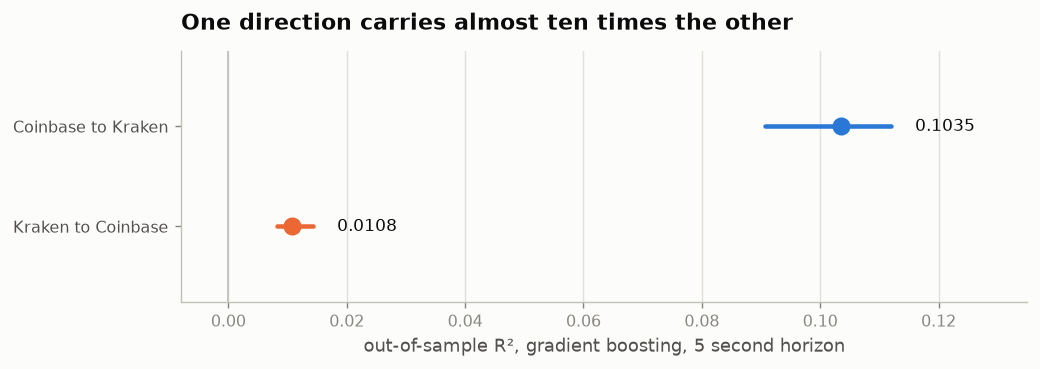

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 2.5))
interval(ax, 1, forward_r2, COINBASE)
interval(ax, 0, backward_r2, KRAKEN)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Kraken to Coinbase", "Coinbase to Kraken"], color=INK2)
ax.set_xlabel("out-of-sample R², gradient boosting, 5 second horizon")
ax.set_title("One direction carries almost ten times the other")
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.75, 1.75)
ax.grid(axis="x", zorder=0)
plt.show()

Coinbase's book forecasts Kraken 9.6 times better than the reverse, and the paired difference,
0.0927, has none of its 20,000 draws at or below zero. Anything symmetric between the two
directions, a shared factor moving both books or a leak in the machinery both runs share, would
inflate both alike and could not open a gap this wide. A leak in one venue's features alone
would not show up here; section 6 tests for that.

The sharper worry is stale data. If a feature row may carry a quote up to five seconds old,
then "forecasting" the next five seconds could be recovering a move that had already happened
at Kraken and not yet been recorded. The staleness cut is a filter on the built feature frame,
so both runs can be repeated with it tightened, down to both books current within 200 ms.

In [10]:
FRESHNESS = DATA / "freshness"
sweep = {}
for f in sorted(FRESHNESS.glob("record_*.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    sweep[r["spec"]["predict_venue"], r["spec"]["max_age_ms"]] = r
for venue, tag in (("kraken", real), ("coinbase", backward)):
    sweep[venue, tag["spec"]["max_age_ms"]] = tag

cuts = sorted({age for _, age in sweep})
print(f"{'cut':>7} {'kept':>7}   {'Coinbase to Kraken':>26}   {'Kraken to Coinbase':>26}   ratio")
for age in cuts:
    ahead, behind = sweep["kraken", age], sweep["coinbase", age]
    f = ahead["pooled"]["gbt"]["r2_vs_zero"]
    b = behind["pooled"]["gbt"]["r2_vs_zero"]
    kept = ahead["n_rows"] / ahead["n_rows_before"]
    print(f"{age:>5}ms {kept:>7.1%}   {f[0]:.5f} [{f[1]:.5f}, {f[2]:.5f}]   "
          f"{b[0]:.5f} [{b[1]:.5f}, {b[2]:.5f}]   {f[0] / b[0]:>4.1f}x")
forward_by_cut = [sweep["kraken", age]["pooled"]["gbt"]["r2_vs_zero"][0] for age in cuts]
print(f"\nacross a {max(cuts) // min(cuts)}-fold range of cuts, the forward R2 runs from "
      f"{min(forward_by_cut):.3f} to {max(forward_by_cut):.3f}")

# Every run in the sweep has to be the same code over the same data as the headline, or
# the comparison is between two different experiments rather than two freshness cuts.
for (venue, age), r in sweep.items():
    p = r["provenance"]
    assert not p["git_dirty"], f"{venue} @ {age}ms was recorded from a dirty tree"
    assert p["builder_fingerprint"] == real["provenance"]["builder_fingerprint"]
    assert p["source_fingerprints"] == real["provenance"]["source_fingerprints"]

tightest = min(cuts)
assert (
    sweep["kraken", tightest]["pooled"]["gbt"]["r2_vs_zero"][0]
    > 5 * sweep["coinbase", tightest]["pooled"]["gbt"]["r2_vs_zero"][0]
), "the asymmetry does not survive the tightest freshness cut"

print()
for tag, venue in (("real", "Kraken"), ("reverse", "Coinbase")):
    print(f"{venue}'s mid moves on {(rows(tag).y != 0).mean():.1%} of scored 5-second bars")

    cut    kept           Coinbase to Kraken           Kraken to Coinbase   ratio
  200ms   54.4%   0.10284 [0.09328, 0.11062]   0.01291 [0.01053, 0.01622]    8.0x
  500ms   75.1%   0.10476 [0.09209, 0.11563]   0.01229 [0.00987, 0.01543]    8.5x
 1000ms   85.3%   0.10377 [0.09421, 0.11148]   0.01154 [0.00951, 0.01461]    9.0x
 5000ms   92.6%   0.10349 [0.09075, 0.11202]   0.01076 [0.00814, 0.01437]    9.6x

across a 25-fold range of cuts, the forward R2 runs from 0.103 to 0.105

Kraken's mid moves on 21.1% of scored 5-second bars
Coinbase's mid moves on 58.8% of scored 5-second bars


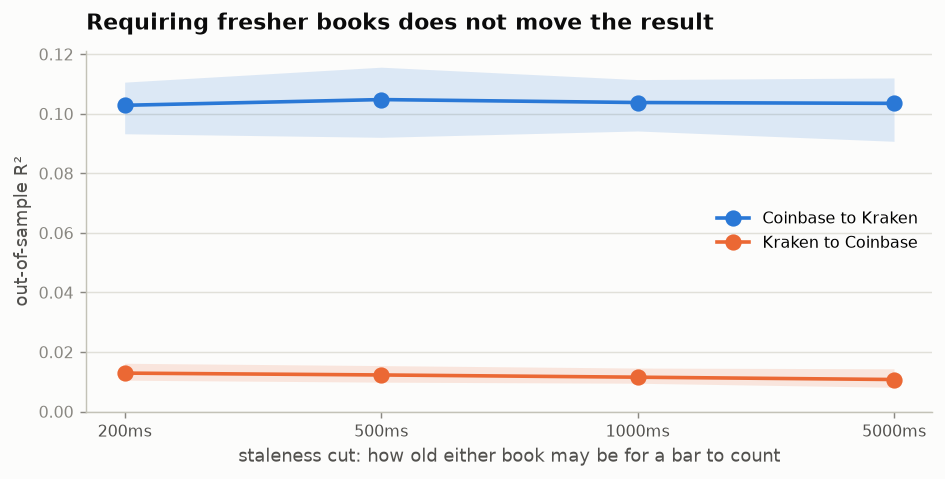

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
xs = range(len(cuts))
for venue, colour, label in (("kraken", COINBASE, "Coinbase to Kraken"),
                             ("coinbase", KRAKEN, "Kraken to Coinbase")):
    pts = [sweep[venue, age]["pooled"]["gbt"]["r2_vs_zero"] for age in cuts]
    ax.plot(xs, [p[0] for p in pts], "o-", color=colour, lw=2, ms=8, label=label, zorder=4)
    ax.fill_between(xs, [p[1] for p in pts], [p[2] for p in pts],
                    color=colour, alpha=0.15, lw=0, zorder=3)
ax.set_xticks(list(xs))
ax.set_xticklabels([f"{age}ms" for age in cuts], color=INK2)
ax.set_xlabel("staleness cut: how old either book may be for a bar to count")
ax.set_ylabel("out-of-sample R²")
ax.set_ylim(bottom=0)
ax.set_title("Requiring fresher books does not move the result")
ax.grid(axis="y", zorder=0)
ax.legend(loc="center right")
plt.show()

Across a 25-fold tightening of the cut the forward R² stays between 0.103 and 0.105, and the
ratio between the directions between 8.0 and 9.6. At 200 ms, which keeps 54.4% of bars, the
forward R² is 0.103.

Neither check separates a venue where news arrives first from one that requotes less often, and
Kraken is the coarser book: its mid moves on 21.1% of five-second bars against Coinbase's 58.8%.
A quote can be current and still rarely updated. That is the question the essay sets aside.

## 6. Leakage: the displaced target

A forecasting pipeline can look good by accident: a feature window that reaches one bar too far,
a fold boundary off by one, a target that shares a term with an input. The test for that whole
family is to break the target on purpose. The same pipeline is rerun with the target displaced
by 3600 bars, an hour, within each day. Every feature, fold, hyperparameter and line of code is
unchanged, and nothing in the inputs can know the displaced return's direction.

In [12]:
null_r2 = confidence_intervals(rows("placebo"))["r2_vs_zero"]
null_hit = confidence_intervals(rows("placebo"))["hit_rate"]

print(f"target displaced by {placebo['spec']['placebo_lag_bars']} bars")
print(f"  R2  {null_r2[0]:8.5f} [{null_r2[1]:.5f}, {null_r2[2]:.5f}]")
print(f"  hit {null_hit[0]:8.4f} [{null_hit[1]:.4f}, {null_hit[2]:.4f}]")

# The gate. Both have to come back indistinguishable from chance.
assert null_r2[1] < 0 < null_r2[2], f"placebo R2 interval misses zero: {null_r2}"
assert null_hit[1] < 0.52, "placebo hit rate is above the long-bias floor"
print("\nthe null holds: R2 straddles zero, hit rate sits at a coin flip")

target displaced by 3600 bars
  R2  -0.00010 [-0.00028, 0.00011]
  hit   0.5035 [0.4958, 0.5124]

the null holds: R2 straddles zero, hit rate sits at a coin flip


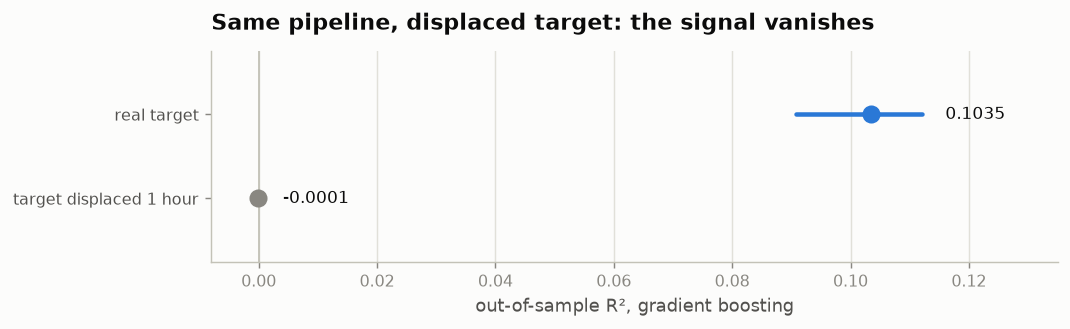

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 2.1))
interval(ax, 1, forward_r2, COINBASE)
interval(ax, 0, null_r2, MUTED)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["target displaced 1 hour", "real target"], color=INK2)
ax.set_xlabel("out-of-sample R², gradient boosting")
ax.set_title("Same pipeline, displaced target: the signal vanishes")
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.75, 1.75)
ax.grid(axis="x", zorder=0)
plt.show()

Displaced, the forecast scores an R² of -0.0001 with an interval straddling zero, and its hit
rate of 50.4% is a coin flip. The test covers alignment leaks, which is what the list above
describes. A leak at the scale of a whole day, such as a statistic computed over the full
session, would survive an hour's displacement and is not covered.

## 7. Calibration

R² against zero already punishes a forecast that is too large overall. It does not show where
along the range of predictions the calibration slips, or separate a small slope error from
noise. We bin the out-of-sample predictions into 20 equal-count buckets and plot each bucket's
mean prediction against its mean realized return, then fit the same line on the raw rows
(Mincer-Zarnowitz), with standard errors clustered by date.

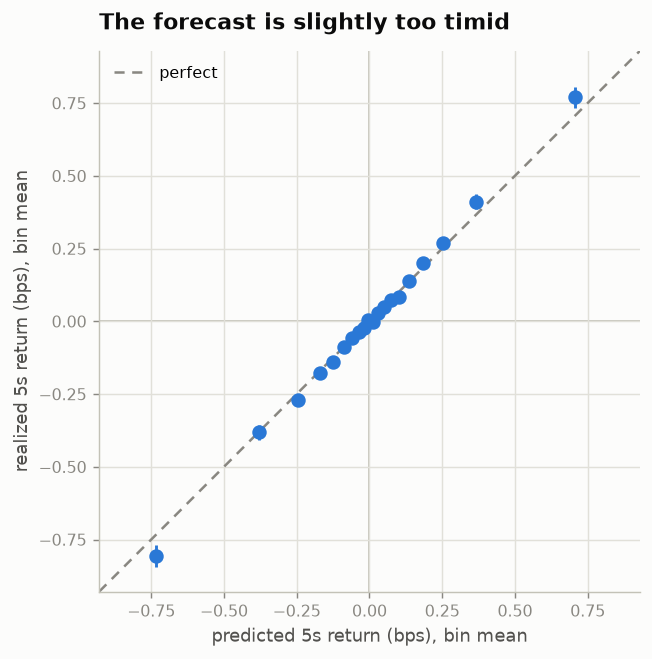

slope across the 20 bins: 1.083
Mincer-Zarnowitz on raw rows, 12 date clusters:
  intercept -0.0003 bps (SE 0.0023)
  slope     1.086 (SE 0.030), t against 1 = 2.90
a forecast of 0.5 bps is followed by 0.54 bps on average


In [14]:
o = rows("real")
edges = np.quantile(o.pred, np.linspace(0, 1, 21))
bucket = np.clip(np.digitize(o.pred, edges[1:-1]), 0, 19)
mean_pred = np.array([o.pred[bucket == b].mean() for b in range(20)])
mean_y = np.array([o.y[bucket == b].mean() for b in range(20)])
sem = np.array([o.y[bucket == b].std() / np.sqrt((bucket == b).sum()) for b in range(20)])
slope = float(np.polyfit(mean_pred, mean_y, 1)[0])

fig, ax = plt.subplots(figsize=(6, 5.4))
lim = max(abs(mean_pred).max(), abs(mean_y).max()) * 1.15
ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2, label="perfect")
ax.errorbar(mean_pred, mean_y, yerr=1.96 * sem, fmt="o", color=COINBASE, ms=7, lw=1.6,
            capsize=0, zorder=4)
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.axvline(0, color=AXIS, lw=1, zorder=1)
ax.set_xlabel("predicted 5s return (bps), bin mean")
ax.set_ylabel("realized 5s return (bps), bin mean")
ax.set_title("The forecast is slightly too timid")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
ax.grid(zorder=0)
ax.legend(loc="upper left")
plt.show()

# Standard errors clustered by date, since bars within one day are not independent draws.
X = np.column_stack([np.ones_like(o.pred), o.pred])
beta = np.linalg.lstsq(X, o.y, rcond=None)[0]
resid = o.y - X @ beta
bread = np.linalg.inv(X.T @ X)
meat = sum(
    np.outer(u, u)
    for u in (X[o.dates == d].T @ resid[o.dates == d] for d in np.unique(o.dates))
)
se = np.sqrt(np.diag(bread @ meat @ bread))

print(f"slope across the 20 bins: {slope:.3f}")
print(f"Mincer-Zarnowitz on raw rows, {len(np.unique(o.dates))} date clusters:")
print(f"  intercept {beta[0]:.4f} bps (SE {se[0]:.4f})")
print(f"  slope     {beta[1]:.3f} (SE {se[1]:.3f}), t against 1 = {(beta[1] - 1) / se[1]:.2f}")
print(f"a forecast of 0.5 bps is followed by {beta[0] + 0.5 * beta[1]:.2f} bps on average")

The slope is 1.086, about three standard errors above one on 12 date clusters, and the
intercept is -0.0003 bps, well inside its standard error. So the forecast is too timid by a
near-constant factor: when it says half a basis point, 0.54 follows on average. A constant
scale error leaves the ranking of bars untouched, and the ranking is what the next section
measures.

## 8. Where the accuracy concentrates

Averaging over every bar hides whether the model knows when it knows. Two definitions make that
measurable. A move counts only if it exceeds half the prevailing spread on Kraken; smaller moves
fall in a dead zone and score as no move. And the model's threshold is set so that it calls a
fixed share of bars, from 2% to 50%, with precision measured at each. Fixing the share is what
makes the comparison with the displaced control fair, since a model that calls few bars is
answering an easier question than one that calls most of them.

In [15]:
spot = coverage_confidence_intervals(rows("real"), 0.02)["up_precision"]
published = real["selectivity"][0]["metrics"]["up_precision"]
assert np.allclose(spot, published, atol=1e-9)
print(f"recomputed precision at 2% coverage: {spot[0]:.4f} [{spot[1]:.4f}, {spot[2]:.4f}] "
      f"(matches the record)")

base = real["base_rates"]["up"]
null_base = placebo["base_rates"]["up"]
print(f"\n{'coverage':>9s} {'real':>25s} {'lift':>6s} {'displaced':>25s} {'lift':>6s}")
for s_real, s_null in zip(real["selectivity"], placebo["selectivity"]):
    r = s_real["metrics"]["up_precision"]
    n = s_null["metrics"]["up_precision"]
    print(f"{s_real['coverage']:>8.0%} {r[0]:7.4f} [{r[1]:.4f}, {r[2]:.4f}] {r[0] / base:5.1f}x "
          f"{n[0]:7.4f} [{n[1]:.4f}, {n[2]:.4f}] {n[0] / null_base:5.1f}x")
# Each run has its own base rate: displacing the target changes which bars cleared half a
# spread, so lift is measured against the run's own floor rather than a shared one.
print(f"\nbase rate, share of bars that rose more than half a spread:"
      f"  real {base:.4f}   displaced {null_base:.4f}")

o = rows("real")
assert np.isclose((o.y > o.threshold).mean(), base)
print(f"dead zone: median threshold {np.median(o.threshold):.4f} bps; "
      f"{(np.abs(o.y) > o.threshold).mean():.1%} of bars clear it, {(o.y != 0).mean():.1%} move")

recomputed precision at 2% coverage: 0.5257 [0.4873, 0.5707] (matches the record)

 coverage                      real   lift                 displaced   lift
      2%  0.5257 [0.4873, 0.5707]   5.2x  0.1403 [0.0862, 0.1770]   1.3x
      5%  0.4565 [0.4285, 0.4789]   4.5x  0.1456 [0.1097, 0.1637]   1.4x
     10%  0.3940 [0.3736, 0.4077]   3.9x  0.1439 [0.1176, 0.1587]   1.4x
     25%  0.3028 [0.2811, 0.3184]   3.0x  0.1215 [0.0942, 0.1464]   1.2x
     50%  0.2290 [0.2041, 0.2475]   2.2x  0.1075 [0.0852, 0.1287]   1.0x

base rate, share of bars that rose more than half a spread:  real 0.1019   displaced 0.1051
dead zone: median threshold 0.0078 bps; 19.8% of bars clear it, 21.1% move


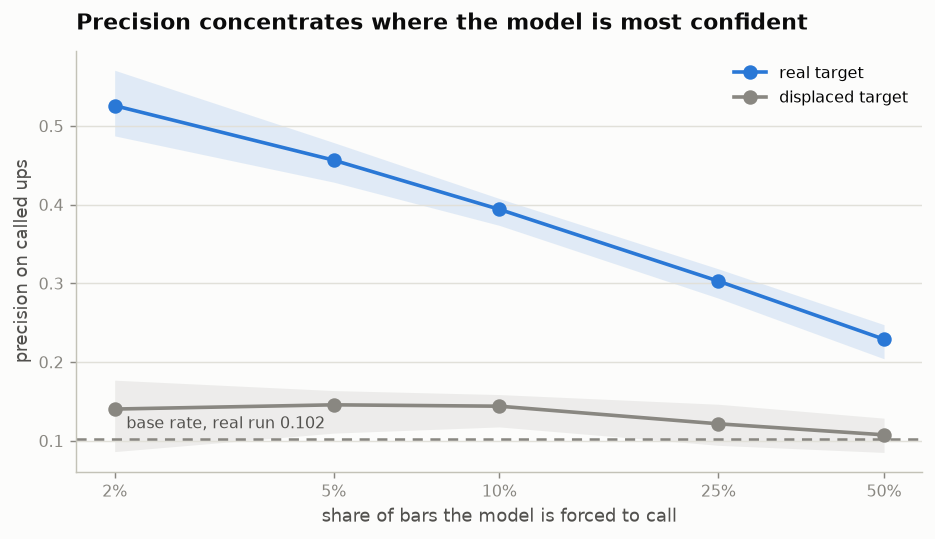

In [16]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
for rec, color, label in [(real, COINBASE, "real target"), (placebo, MUTED, "displaced target")]:
    cov = [s["coverage"] for s in rec["selectivity"]]
    band = np.array([s["metrics"]["up_precision"] for s in rec["selectivity"]])
    ax.fill_between(cov, band[:, 1], band[:, 2], color=color, alpha=0.13, lw=0)
    ax.plot(cov, band[:, 0], "-o", color=color, lw=2, ms=7, label=label, zorder=4)
ax.axhline(base, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
ax.text(0.021, base + 0.014, f"base rate, real run {base:.3f}", fontsize=9, color=INK2)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.02, 0.05, 0.10, 0.25, 0.50])
ax.set_xticklabels(["2%", "5%", "10%", "25%", "50%"])
ax.set_xlabel("share of bars the model is forced to call")
ax.set_ylabel("precision on called ups")
ax.set_title("Precision concentrates where the model is most confident")
ax.grid(axis="y", zorder=0)
ax.legend(loc="upper right")
plt.show()

Forced to call half of all bars, the model's precision on up-calls is 2.2 times the base rate.
On its most confident 2% it is 5.2 times. That steady climb is what a genuine ranking produces.

The displaced control climbs too, from 1.0 to 1.4 times its base rate, and then stops, flat
where the real curve is steepest. It sits above its base rate because volatility clusters: a
model can learn to call more often when the book is active, and moves are larger then. That
ranks bars by *when* something will happen, not *which way*, and only the second is worth
anything here. Each run is measured against its own base rate, since displacing the target
changes which bars clear half a spread.

Half a spread is a low bar on a book this tight. The median threshold is 0.0078 bps, and 19.8%
of bars clear it against the 21.1% that move at all, so precision here is close to precision on
any move.

## 9. The information share: sampling, lags and assumptions

The essay fits the error-correction model on one-second bars with ten lags and reports
Hasbrouck's bounds on Coinbase's share. crosstick fitted the same model on one-, five- and
thirty-second bars, and the record keeps every daily estimate.

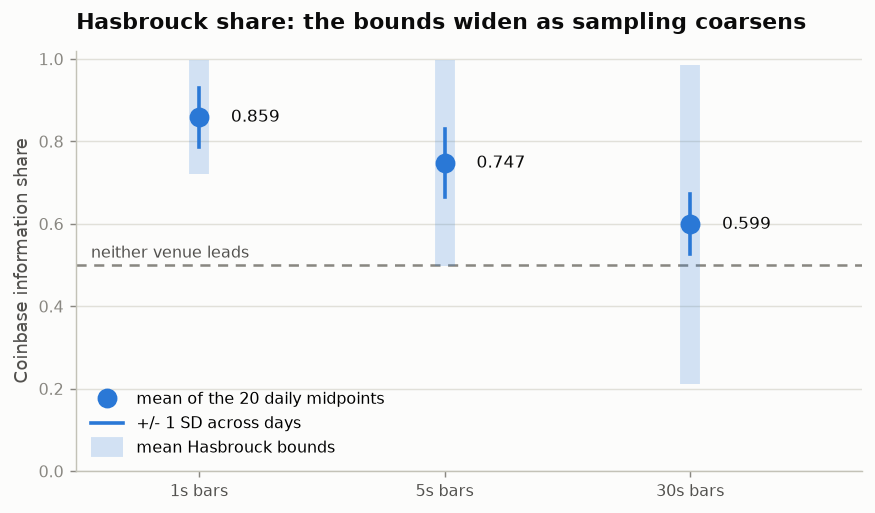

bars      mean bounds  width        midpoint  corr  lower bound below 0.5
  1s [0.720, 0.997]  0.278 0.859 +/- 0.071  0.49  1 of 20 days
  5s [0.498, 0.997]  0.499 0.747 +/- 0.082  0.71  9 of 20 days
 30s [0.212, 0.985]  0.773 0.599 +/- 0.072  0.90  18 of 20 days


In [17]:
blocks = {b["stride"]: b["estimates"] for b in real["infoshare"]}

fig, ax = plt.subplots(figsize=(7.8, 4.2))
for i, est in enumerate(blocks.values()):
    bounds = np.array([e["bounds"][0] for e in est], dtype=float)
    mids = bounds.mean(axis=1)
    band = ax.plot([i, i], [bounds[:, 0].mean(), bounds[:, 1].mean()], color=COINBASE, lw=11,
                   alpha=0.20, solid_capstyle="butt", zorder=3)[0]
    spread = ax.plot([i, i], [mids.mean() - mids.std(), mids.mean() + mids.std()],
                     color=COINBASE, lw=2, zorder=4)[0]
    dot = ax.plot([i], [mids.mean()], "o", color=COINBASE, ms=10, zorder=5)[0]
    ax.text(i + 0.13, mids.mean(), f"{mids.mean():.3f}", va="center", fontsize=9.5, color=INK)
ax.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
ax.text(-0.44, 0.518, "neither venue leads", fontsize=9, color=INK2)
ax.set_xticks(range(len(blocks)))
ax.set_xticklabels([f"{stride}s bars" for stride in blocks], color=INK2)
ax.set_ylim(0, 1.02)
ax.set_xlim(-0.5, len(blocks) - 0.3)
ax.set_ylabel("Coinbase information share")
ax.set_title("Hasbrouck share: the bounds widen as sampling coarsens")
ax.grid(axis="y", zorder=0)
ax.legend([dot, spread, band],
          ["mean of the 20 daily midpoints", "+/- 1 SD across days", "mean Hasbrouck bounds"],
          loc="lower left")
plt.show()

print(f"{'bars':>4} {'mean bounds':>16} {'width':>6} {'midpoint':>15} {'corr':>5}  "
      f"lower bound below 0.5")
for stride, est in blocks.items():
    b = np.array([e["bounds"][0] for e in est], dtype=float)
    mid = b.mean(axis=1)
    corr = np.mean([e["residual_corr"] for e in est])
    print(f"{stride:>3}s [{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}] "
          f"{(b[:, 1] - b[:, 0]).mean():6.3f} {mid.mean():.3f} +/- {mid.std():.3f} {corr:5.2f}  "
          f"{(b[:, 0] < 0.5).sum()} of {len(est)} days")

At one-second bars the averaged bounds are [0.720, 0.997]. They widen as the sampling
coarsens, because more of the venues' surprises land in the same bar: the residual correlation
rises from 0.49 at one second to 0.71 at five and 0.90 at thirty, and the number of days whose
lower bound falls below one half goes from 1 to 9 to 18 of 20. Over thirty seconds both venues
have reacted to almost anything, so the data can no longer say which reacted first. A share
quoted without its sampling interval is not an answer.

In [18]:
venues = tuple(real["spec"]["infoshare_venues"])
days = {d: np.log(g.select([f"{v}_mid" for v in venues]).to_numpy())
        for (d,), g in prices.group_by(["date"], maintain_order=True)}

for lags in (5, 10, 20):
    b = np.array([information_shares(p, venues, lags).bounds[0] for p in days.values()])
    print(f"{lags:>2} lags, one-second bars: bounds averaged over the days "
          f"[{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}]")


def adf_t(x, lags=10):
    """Augmented Dickey-Fuller t-statistic, with a constant and `lags` lagged differences."""
    dx = np.diff(x)
    t = np.arange(lags, len(dx))
    X = np.column_stack([x[:-1][t], *(dx[t - k] for k in range(1, lags + 1)), np.ones(len(t))])
    coef, *_ = np.linalg.lstsq(X, dx[t], rcond=None)
    resid = dx[t] - X @ coef
    var = resid @ resid / (len(t) - X.shape[1]) * np.linalg.inv(X.T @ X)[0, 0]
    return coef[0] / np.sqrt(var)


# Asymptotic Dickey-Fuller critical values with a constant (MacKinnon 1996). The basis
# imposes its cointegrating vector rather than estimating it, so they apply as they stand.
CRIT_1, CRIT_5 = -3.43, -2.86
basis = np.array([adf_t(p[:, 0] - p[:, 1]) for p in days.values()])
levels = np.array([[adf_t(p[:, 0]), adf_t(p[:, 1])] for p in days.values()])
print(f"\nADF t-statistics over {len(days)} days; critical values {CRIT_1} (1%), {CRIT_5} (5%)")
print(f"  the basis, log Coinbase minus log Kraken: {basis.min():.1f} to {basis.max():.1f}")
print(f"  each venue's log price:                   {levels.min():.2f} to {levels.max():.2f}")
assert (basis < CRIT_1).all() and not (levels < CRIT_5).any()

# Gonzalo-Granger: Coinbase's weight is Kraken's pull over the two pulls combined. The pulls
# are signed as in the essay, each the share of the gap its own venue closes per second.
one_second = blocks[1]
pulls = np.array([[-e["alpha"][0], e["alpha"][1]] for e in one_second])
gg = np.array([e["component_shares"][0] for e in one_second])
assert np.allclose(gg, pulls[:, 1] / pulls.sum(axis=1))
print(f"\nCoinbase's pull {pulls[:, 0].mean():.1%} a second on average, day-to-day SD "
      f"{pulls[:, 0].std(ddof=1):.1%}, below zero on {(pulls[:, 0] < 0).sum()} days; "
      f"Kraken's is {pulls[:, 1].mean() / pulls[:, 0].mean():.0f} times as large")
print(f"Gonzalo-Granger share, Coinbase: {gg.min():.2f} to {gg.max():.2f}, average "
      f"{gg.mean():.3f}, above 1 on {(gg > 1).sum()} days")

 5 lags, one-second bars: bounds averaged over the days [0.726, 0.997]


10 lags, one-second bars: bounds averaged over the days [0.720, 0.997]


20 lags, one-second bars: bounds averaged over the days [0.729, 0.998]



ADF t-statistics over 20 days; critical values -3.43 (1%), -2.86 (5%)
  the basis, log Coinbase minus log Kraken: -44.8 to -15.8
  each venue's log price:                   -2.60 to 0.76

Coinbase's pull 0.2% a second on average, day-to-day SD 0.3%, below zero on 6 days; Kraken's is 21 times as large
Gonzalo-Granger share, Coinbase: 0.87 to 1.11, average 0.965, above 1 on 6 days


The lag order was set at ten to span the forecast's five-second horizon, not chosen by a
criterion. Halving or doubling it moves the averaged bounds by less than a hundredth:
[0.726, 0.997] at five lags, [0.729, 0.998] at twenty.

The model assumes each log price wanders without settling while the gap between them keeps
coming back, with the cointegrating vector imposed as (1, -1) rather than estimated. Both halves
hold on every day. An augmented Dickey-Fuller test rejects a unit root in the gap at 1% on all
20 days, with t-statistics no higher than -15.8 against a critical value of -3.43, and does not
reject one at 5% in either venue's log price on any day.

**The Gonzalo-Granger share is computed but not headlined.** Coinbase's share is Kraken's pull
divided by the two pulls combined, and Coinbase's pull is small, a twenty-first of Kraken's,
with a day-to-day spread of 0.3% against an average of 0.2%. On the 6 days its estimate dips
below zero, the share exceeds 1. Over the 20 days it runs from 0.87 to 1.11 and averages 0.965,
pointing the same way as Hasbrouck's bounds, but a daily value above 1 cannot be read as a
share.

## 10. Timing: whose clock?

Every price in this study is stamped when it reached our capture machine. That is when a
trader there could first have acted on it, but it also folds in how long each venue's updates
take to arrive, and if Kraken's take longer, Coinbase starts every second slightly ahead. This
section measures that head start, finds out what each exchange's own stamp marks, and refits
the information share and the essay's jump study without it.

These measurements come from crosstick's lake rather than from a run record.
`scripts/extract_clocks.py` read both stamps of every book update there, and
`scripts/export_clocks.py` published the result only after the arrival clock, rebuilt from the
same tables, matched the published prices bit for bit on every bar.

In [19]:
clocks = json.loads((DATA / "clocks.json").read_text(encoding="utf-8"))
delay = {venue: np.array([d["book_delay_ms"]["p50"] for d in by_day.values()])
         for venue, by_day in clocks["venues"].items()}
print("median time from a book update's own stamp to its arrival here")
for venue, ms in delay.items():
    print(f"  {venue:9s} {np.median(ms):5.1f} ms on the median day, {ms.min():.1f} to {ms.max():.1f} by day")
extra = delay["kraken"] - delay["coinbase"]
print(f"  Kraken's arrive {np.median(extra):.0f} ms after Coinbase's on the median day, "
      f"{extra.min():.0f} to {extra.max():.0f} ms by day")

print("\nwhen a trade takes out the best price, does the book update carry the trade's own stamp?")
for venue, by_day in clocks["venues"].items():
    matched = sum(d["stamp_test"]["matched"] for d in by_day.values())
    equal = sum(d["stamp_test"]["equal"] for d in by_day.values())
    print(f"  {venue:9s} identical on {equal / matched:5.1%} of {matched:,} such moves")

# The text below quotes these.
tests = {v: [d["stamp_test"] for d in by_day.values()] for v, by_day in clocks["venues"].items()}
assert sum(t["equal"] for t in tests["coinbase"]) == 0
kraken_equal = sum(t["equal"] for t in tests["kraken"]) / sum(t["matched"] for t in tests["kraken"])
assert f"{np.median(extra):.0f} {extra.min():.0f} {extra.max():.0f} {kraken_equal:.1%}" == "43 38 50 70.1%"

median time from a book update's own stamp to its arrival here
  coinbase   24.4 ms on the median day, 17.4 to 36.6 by day
  kraken     68.1 ms on the median day, 56.2 to 77.4 by day
  Kraken's arrive 43 ms after Coinbase's on the median day, 38 to 50 ms by day

when a trade takes out the best price, does the book update carry the trade's own stamp?
  coinbase  identical on  0.0% of 66,852 such moves
  kraken    identical on 70.1% of 150,464 such moves


Kraken's book updates reach us 43 ms after Coinbase's on the median day, and between 38 and
50 ms after on every day. Each delay is measured against the venue's own stamp, so it also
carries any error in our machine's clock, but that error is shared by both venues and cancels
in the difference.

The two stamps do not mark the same moment. Coinbase documents its stamp as the time the
message was sent. Kraken documents its stamp as the book order update timestamp, which leaves
it open, so the cell above tests it. When a trade takes out the best price, the book update
that removes that price should carry the trade's own stamp if both mark the same event in the
matching engine. On Kraken the two are identical on 70.1% of 150,464 such moves, and on
Coinbase on none. Kraken stamps the change in its book, and Coinbase stamps the sending, some
time after its book changed.

That makes the exchanges' own stamps the clock most favourable to Kraken: each Kraken update
sits at the moment its book changed, each Coinbase update at the later moment Coinbase sent
it. If the two exchanges' clocks agree, timing both by when their books actually changed could
only move Coinbase earlier. A second check needs no stamps at all: move Kraken's prices earlier
by a fixed amount, as if every update had happened that long before it reached us, and watch
what the shift does.

In [20]:
retimed = pl.read_parquet(DATA / "prices_retimed.parquet")


def timed(*series):
    """The published prices with each named re-timed series swapped in for its venue."""
    panel = prices
    for name in series:
        venue = name.split("_")[0]
        swap = retimed.filter(pl.col("series") == name).select("date", "ts_ns", "mid")
        panel = (panel.join(swap, on=["date", "ts_ns"], how="left")
                 .with_columns(pl.coalesce("mid", f"{venue}_mid").alias(f"{venue}_mid"))
                 .drop("mid"))
    return panel.sort("ts_ns")


def catch_up(panel):
    """The essay's jump study: Kraken's move ten seconds after a Coinbase jump of 2 bp or
    more, as a share of Coinbase's."""
    ts, day = panel["ts_ns"].to_numpy(), panel["date"].to_numpy()
    logp = np.log(panel.select(["coinbase_mid", "kraken_mid"]).to_numpy()) * 1e4
    follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
    stretch = np.cumsum(~follows)
    move = np.r_[np.nan, np.diff(logp[:, 0])]
    at = np.flatnonzero(follows & (np.abs(move) >= 2.0))
    at = at[(at >= 10) & (at + 15 < len(logp))]
    at = at[stretch[at - 10] == stretch[at + 15]]
    ten = (logp[at + 10] - logp[at - 1]) * np.sign(move[at])[:, None]
    return ten[:, 1].mean() / ten[:, 0].mean()


def measure(panel, stride=1):
    """Coinbase's daily Hasbrouck bounds and both venues' daily pulls."""
    fits = [information_shares(np.log(g.select(["coinbase_mid", "kraken_mid"]).to_numpy())[::stride],
                               venues)
            for _, g in panel.group_by(["date"], maintain_order=True)]
    bounds = np.array([f.bounds[0] for f in fits])
    pulls = np.array([[-f.alpha[0], f.alpha[1]] for f in fits])
    return bounds, pulls


shifts = clocks["shifts_ms"]
clock_rows = {"on arrival, as published": prices,
              "on each exchange's own stamp": timed("coinbase_exchange", "kraken_exchange")}
clock_rows |= {f"Kraken shifted {s} ms earlier": timed(f"kraken_plus_{s}ms") for s in shifts}
results = {}
print(f"{'prices timed':30s} {'Coinbase share, 1s':>18s} {'lower < 0.5':>12s} "
      f"{'Kraken pull / Coinbase':>23s} {'catch-up':>9s}")
for name, panel in clock_rows.items():
    bounds, pulls = measure(panel)
    ratio = pulls[:, 1].mean() / pulls[:, 0].mean()
    results[name] = (bounds.mean(axis=0), ratio, catch_up(panel))
    share = f"[{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]"
    below = f"{(bounds[:, 0] < 0.5).sum()} of 20"
    print(f"{name:30s} {share:>18s} {below:>12s} {f'{ratio:.0f}x':>23s} {results[name][2]:>9.0%}")

# The published row is the essay's: the same bounds, pull ratio and catch-up it quotes.
published = results["on arrival, as published"]
assert f"[{published[0][0]:.3f}, {published[0][1]:.3f}] {published[1]:.0f} {published[2]:.0%}" \
    == "[0.720, 0.997] 21 91%"

def quoted(name):
    (low, high), ratio, caught = results[name]
    return f"[{low:.3f}, {high:.3f}] {ratio:.0f} {caught:.0%}"


# The text below quotes these.
assert quoted("on each exchange's own stamp") == "[0.702, 0.997] 15 90%"
assert quoted("Kraken shifted 40 ms earlier") == "[0.705, 0.997] 16 90%"
assert quoted("Kraken shifted 200 ms earlier") == "[0.647, 0.989] 6 85%"

exchange = clock_rows["on each exchange's own stamp"]
for stride in (5, 30):
    on_stamp, as_published = measure(exchange, stride)[0], measure(prices, stride)[0]
    print(f"\n{stride}s bars: [{on_stamp[:, 0].mean():.3f}, {on_stamp[:, 1].mean():.3f}] on the "
          f"exchanges' stamps, [{as_published[:, 0].mean():.3f}, {as_published[:, 1].mean():.3f}] "
          f"as published", end="")
print()

prices timed                   Coinbase share, 1s  lower < 0.5  Kraken pull / Coinbase  catch-up


on arrival, as published           [0.720, 0.997]      1 of 20                     21x       91%


on each exchange's own stamp       [0.702, 0.997]      1 of 20                     15x       90%


Kraken shifted 20 ms earlier       [0.712, 0.997]      1 of 20                     19x       91%


Kraken shifted 40 ms earlier       [0.705, 0.997]      1 of 20                     16x       90%


...

Kraken shifted 100 ms earlier      [0.679, 0.995]      2 of 20                     11x       89%


Kraken shifted 150 ms earlier      [0.660, 0.992]      3 of 20                      8x       87%


Kraken shifted 200 ms earlier      [0.647, 0.989]      3 of 20                      6x       85%



5s bars: [0.501, 0.997] on the exchanges' stamps, [0.498, 0.997] as published


30s bars: [0.212, 0.985] on the exchanges' stamps, [0.212, 0.985] as published


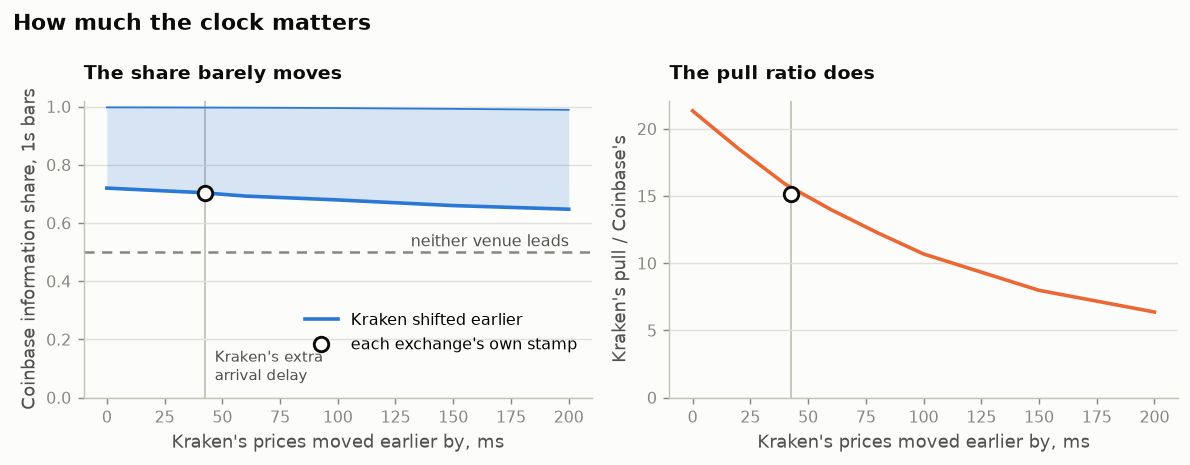

In [21]:
x = [0, *shifts]
sweep = [results["on arrival, as published"],
         *(results[f"Kraken shifted {s} ms earlier"] for s in shifts)]
stamp = results["on each exchange's own stamp"]
gap_ms = np.median(extra)

fig, (left, right) = plt.subplots(1, 2, figsize=(9.2, 3.6))
low, high = np.array([b for b, _, _ in sweep]).T
left.fill_between(x, low, high, color=COINBASE, alpha=0.18, lw=0, zorder=2)
left.plot(x, low, color=COINBASE, lw=2, zorder=3, label="Kraken shifted earlier")
left.plot(x, high, color=COINBASE, lw=1, zorder=3)
left.plot([gap_ms], [stamp[0][0]], "o", mfc=SURFACE, mec=INK, mew=1.6, ms=8, zorder=4,
          label="each exchange's own stamp")
left.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=1)
left.text(x[-1], 0.52, "neither venue leads", ha="right", fontsize=9, color=INK2)
left.set_ylim(0, 1.02)
left.set_ylabel("Coinbase information share, 1s bars")
left.set_title("The share barely moves", fontsize=10.5)

right.plot(x, [r for _, r, _ in sweep], color=KRAKEN, lw=2, zorder=3)
right.plot([gap_ms], [stamp[1]], "o", mfc=SURFACE, mec=INK, mew=1.6, ms=8, zorder=4)
right.set_ylim(0, None)
right.yaxis.set_major_locator(mpl.ticker.MultipleLocator(5))
right.set_ylabel("Kraken's pull / Coinbase's")
right.set_title("The pull ratio does", fontsize=10.5)

for ax in (left, right):
    ax.axvline(gap_ms, color=AXIS, lw=1, zorder=1)
    ax.set_xlabel("Kraken's prices moved earlier by, ms")
    ax.grid(axis="y", zorder=0)
left.text(gap_ms + 4, 0.06, "Kraken's extra\narrival delay", fontsize=8.5, color=INK2)
left.legend(loc="lower right", bbox_to_anchor=(1.0, 0.1))
fig.suptitle("How much the clock matters", x=0.01, ha="left", fontsize=12, fontweight="bold",
             color=INK)
fig.tight_layout()
plt.show()

On the exchanges' own stamps, Coinbase's share averages [0.702, 0.997] against [0.720, 0.997]
as published, its lower bound still falls below one half on only 1 of 20 days, and Kraken
covers 90% of a Coinbase jump within ten seconds against 91%. At five-second bars the bounds
are [0.501, 0.997] against [0.498, 0.997], and at thirty they agree to three decimals.

The shift says the same from the other side. Moving Kraken's prices 40 ms earlier, about its
extra delay, lands close to where the exchange stamps do. Moving them 200 ms earlier, more
than four times that delay, still leaves Coinbase's share at [0.647, 0.989], with Kraken
covering 85% of a Coinbase jump. The lead is not an artefact of where we listened from.

What the clock does move is the ratio of the two pulls: Kraken pulls 21 times as hard as
Coinbase on arrival, 15 times on the exchanges' stamps, and 6 times at a 200 ms shift.
Coinbase's pull is close to zero, so the ratio divides by a small number and anything that
nudges it moves the ratio a long way. That Kraken does nearly all the closing holds on every
clock; the essay's 21 is the arrival clock's.

## 11. Everything, recomputed

The cell below recomputes every published number from the committed files and checks it against
the record: the forecasts' scores from the prediction rows, and every daily information-share
estimate from the one-second prices, refitted with crosstick's own estimator. CI executes this
notebook, so a number that drifts fails the build rather than quietly rendering a different
result.

In [22]:
checks = []

for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    pooled_tag = confidence_intervals(rows(tag))
    for metric in ("r2_vs_zero", "hit_rate", "gross_bps_per_trade"):
        got, want = pooled_tag[metric], rec["pooled"]["gbt"][metric]
        ok = np.allclose(got, want, atol=1e-9, equal_nan=True)
        checks.append(ok)
        print(f"{tag:8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
              f"{'matches record' if ok else 'DIFFERS'}")

classes = class_confidence_intervals(rows("real"))
for metric in ("up_precision", "down_precision"):
    got, want = classes[metric], real["classes"]["gbt"][metric]
    ok = np.allclose(got, want, atol=1e-9)
    checks.append(ok)
    print(f"{'real':8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
          f"{'matches record' if ok else 'DIFFERS'}")

refits = []
for block in real["infoshare"]:
    for want in block["estimates"]:
        got = information_shares(days[want["date"]][:: block["stride"]], venues, block["lags"])
        refits.append(got.n == want["n"]
                      and np.allclose(got.alpha, want["alpha"], rtol=1e-9, atol=0)
                      and np.allclose(got.bounds, want["bounds"], rtol=0, atol=1e-9))
print(f"\ninformation share: {sum(refits)} of {len(refits)} daily estimates, across "
      f"{len(real['infoshare'])} sampling intervals, refitted from the prices and matching")

assert all(checks) and all(refits), "a published number does not reproduce from the files"
print(f"{len(checks)} forecast scores and {len(refits)} information-share estimates "
      f"recomputed, all matching")

real     r2_vs_zero             0.10349 [ 0.09075,  0.11202]  matches record
real     hit_rate               0.75719 [ 0.73511,  0.78052]  matches record
real     gross_bps_per_trade    0.20024 [ 0.15078,  0.24480]  matches record
reverse  r2_vs_zero             0.01076 [ 0.00814,  0.01437]  matches record
reverse  hit_rate               0.58163 [ 0.56915,  0.59704]  matches record
reverse  gross_bps_per_trade    0.09110 [ 0.07484,  0.10704]  matches record


placebo  r2_vs_zero            -0.00010 [-0.00028,  0.00011]  matches record
placebo  hit_rate               0.50352 [ 0.49580,  0.51244]  matches record
placebo  gross_bps_per_trade   -0.00088 [-0.00379,  0.00231]  matches record
real     up_precision           0.16165 [ 0.13223,  0.18758]  matches record
real     down_precision         0.15363 [ 0.12165,  0.18260]  matches record



information share: 60 of 60 daily estimates, across 3 sampling intervals, refitted from the prices and matching
11 forecast scores and 60 information-share estimates recomputed, all matching


`gross_bps_per_trade` is the average five-second move in the direction the model called, before
fees, the spread or any question of being filled. It is in the record because crosstick computes
it, and it is not a trading result.

---

**Data and code.** The predictions, prices and run records in `data/` were exported from
[crosstick](https://github.com/ryanp2718/crosstick) at commit `fb7a22d`, which is also the
commit this notebook installs its analysis code from. The re-timed prices and the clock
measurements were read from crosstick's lake by `scripts/extract_clocks.py`. The platform side,
an ingest-to-lake pipeline for three exchanges with reconstructed order books and a
cross-exchange NBBO, lives there.

**References.** Hasbrouck, "One security, many markets: determining the contributions to price
discovery", Journal of Finance 50(4), 1995. Gonzalo and Granger, "Estimation of common
long-memory components in cointegrated systems", Journal of Business and Economic Statistics
13(1), 1995. MacKinnon, "Numerical distribution functions for unit root and cointegration
tests", Journal of Applied Econometrics 11(6), 1996.